# Fourier transform of gravitational field produced by a rectangular prism

This code illustrates the Fourier transform of the gravitational field produced by a homogeneous rectangular prism.

### Things we have to import

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from gravmag.models import rectangular_prism as rp
from gravmag import plot_functions as plf

In [3]:
from gravmag import filters, convolve, transforms

In [4]:
from scipy.fft import ifftshift, fftshift

### Model

In [5]:
# Create a model formed by prisms
model = np.array([[-500., 500., 400, 1600., 10., 1010.]])

# density of each prism
density = np.array([1])

### Points were we compute the synthetic data

In [6]:
# number of points along x and y
shape = (500, 500)

# minimum x, maximum x, minimum y and maximum y
area = [-14000, 14000, -13000, 15000]

# Grid spacing
dx = (area[1] - area[0])/(shape[0]-1)
dy = (area[3] - area[2])/(shape[1]-1)

# coordinates 
xp = np.linspace(area[0], area[1], shape[0])
yp = np.linspace(area[2], area[3], shape[1])
yp, xp = np.meshgrid(yp, xp)
yp = np.ravel(yp)
xp = np.ravel(xp)

# constant vertical coordinate
z0 = -15

zp = np.zeros_like(yp) + z0

coordinates = np.vstack([xp, yp, zp])

In [7]:
print(dx, dy)

56.1122244488978 56.1122244488978


### Synthetic residual field

In [8]:
# Compute the magnetic field components
U = rp.grav(coordinates=coordinates, prisms=model, density=density, field='potential')

In [9]:
U_mean = np.mean(U)

In [10]:
U_mean

9.731955135332724e-06

In [21]:
# compute 2D Fourier transform of U without padding
FT_U = transforms.DFT(data=U.reshape(shape))*10.
#FT_U = fftshift(FT_U)*dx*dy
#FT_U = FT_U*dx*dy

In [12]:
# compute wavenumbers
kx, ky, kz = transforms.wavenumbers(FT_U.shape, dx, dy)

### Compute the amplitude spectrum

In [13]:
FT_U_closed_form = transforms.FT_grav_potential_rectangular_prism(
    shape, dx, dy, model, density, z0
)

In [14]:
FT_U_closed_form.shape

(500, 500)

In [15]:
U_predicted = fftshift(transforms.IDFT(FT_U_closed_form))
#U_predicted = fftshift(transforms.IDFT(FT_U_closed_form)) + U_mean
#U_predicted = transforms.IDFT(FT_U_closed_form)
#U_predicted = transforms._unpad(U_predicted)

In [16]:
U_predicted.shape

(500, 500)

### Plot the results

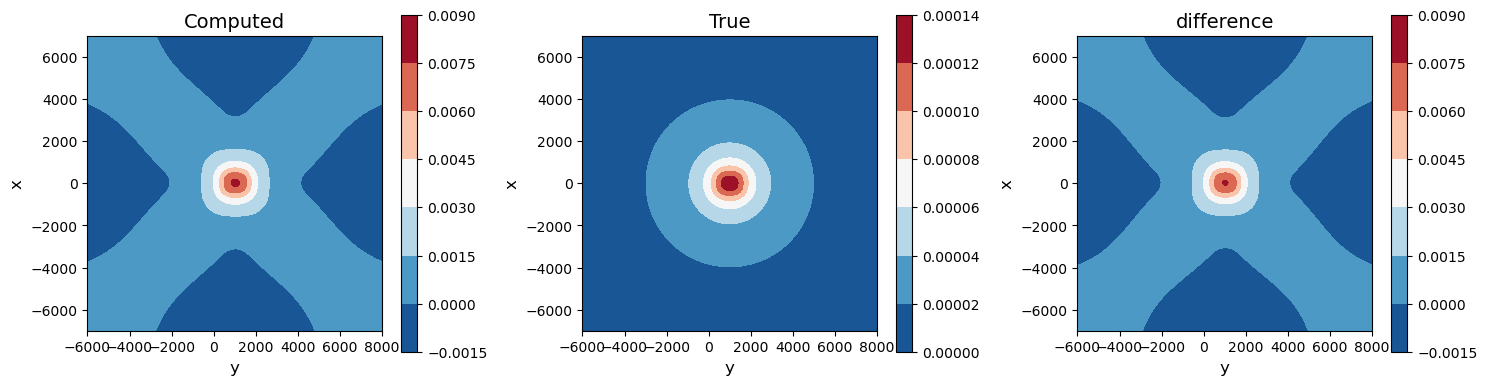

In [17]:
true_fields = [U.reshape(shape)]
computed_fields = [U_predicted]

bounds, diffs = plf.bounds_diffs(computed_fields, true_fields)

fields = plf.fields_list(computed_fields, true_fields, diffs)

titles = ['Computed', 'True', 'difference']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        yp.reshape(shape), 
        xp.reshape(shape), 
        fields[w], 
        cmap='RdBu_r',
        #vmin = -bounds[w], vmax = bounds[w]
    )
    plt.colorbar()
    plf.model_boundaries(model, m2km=True)
    plt.ylim(-7000, 7000)
    plt.xlim(-6000, 8000)
    plt.xlabel('y', fontsize=12)
    plt.ylabel('x', fontsize=12)

plt.tight_layout()

plt.show()

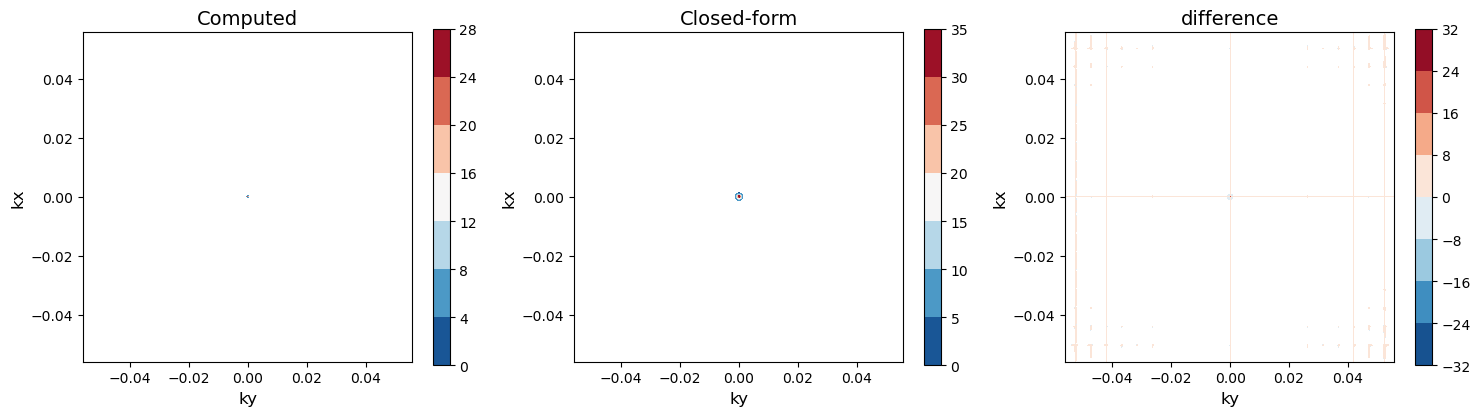

In [22]:
closed_form_FT_U = [np.abs(FT_U_closed_form)]
computed_FT_U = [np.abs(FT_U)]

bounds, diffs = plf.bounds_diffs(computed_FT_U, closed_form_FT_U)

fields = plf.fields_list(computed_FT_U, closed_form_FT_U, diffs)

titles = ['Computed', 'Closed-form', 'difference']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        ky, 
        kx, 
        fields[w], 
        cmap='RdBu_r',
        #vmin = -bounds[w], vmax = bounds[w]
    )
    plt.colorbar()
    plt.ylim(kx.min(), kx.max())
    plt.xlim(ky.min(), ky.max())
    plt.xlabel('ky', fontsize=12)
    plt.ylabel('kx', fontsize=12)

plt.tight_layout()

plt.show()